# Development image registartion with simpleElastix

## TODO:

- [ ] load data
- [ ] test registration
- [x] mask data before registration (black background from rotation)
- [ ] obtain suitable and save masks

In [19]:
#modules
import xarray as xr
import json
import os
import socket
host = socket.gethostname()
import matplotlib.pyplot as plt
import SimpleITK as sitk
import numpy as np

# paths
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    # toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppath = '/mnt/SSD/fische_r/COELY'
    
path_01_4D = os.path.join(toppath, '01_rotated_3p1D')

## Test: load two operando scans and register

In [44]:
sample = '5II'
file = '01_'+sample+'_rotated_3p1D.nc'
imagepath = os.path.join(path_01_4D, file)
data = xr.open_dataset(imagepath)
images = [im for im in data.keys() if im[3:7] == 'imag']
images.sort()

In [45]:
image1 = images[5]
image2 = images[0]

In [93]:
im1 = data[image1].data
im2 = data[image2].data

mask = np.zeros(im1.shape, dtype=np.uint8)
mask[50:-50,50:-50,50:-50] = 1 #seems ok as mask!

In [67]:
data.close()

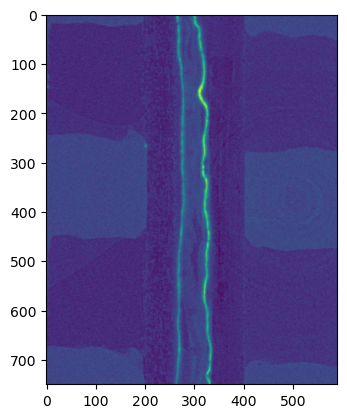

In [69]:
plt.imshow(im1[...,500])

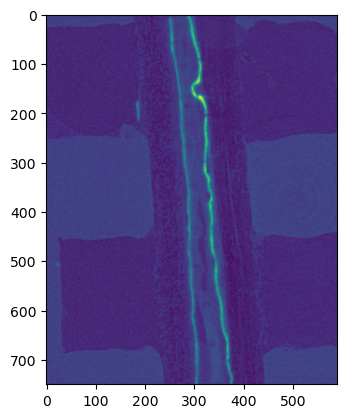

In [65]:
plt.imshow(im2[50:-50,40:-40,500])

In [78]:
# copied from Salvo's and Mayank's code
# TODO: adapat for own purpose, i.e. masking, parallelization, affine registration, transformation matrix
def register_images_general(im_fixed, im_tomove, parameter_map, verbose=False, im_mask=None):

    r"""
    General registration for 2D or 3D images
    This function allows control over the parameter map
    
         
    Parameters
    ----------     
    im_fixed : numpy.ndarray
        Fixed image
    im_tomove: numpy.ndarray
        Image to register (to im_fixed)
    parameter_map: sitk.ParameterMap
        Parameters map object as obtained from sitk.GetParameterMap
    verbose : bool, optional (default=False)
        Enable/Disable log to console 
    im_mask : numpy.ndarray (default=None)
        Mask for sampling points (required). 
        im_mask has same dimensions as im_fixed 
        The mask ndarray has 1 and 0. 1 values denote the area where
        points for the registration are sampled.    
    Returns
    -------
    im_aligned : numpy.ndarray
        Aligned image having same dimensions of im_tomove
                 
    Notes
    -----
    To have further info on parameter maps, go to:
    https://simpleelastix.readthedocs.io/ParameterMaps.html
    For more details on the different parameters, download:
    https://elastix.lumc.nl/download/elastix_manual_v4.8.pdf
    """


    itk_image_fixed = sitk.GetImageFromArray(im_fixed)
    itk_image_tomove = sitk.GetImageFromArray(im_tomove)
           
    elastixImageFilter = sitk.ElastixImageFilter()
    elastixImageFilter.SetFixedImage(itk_image_fixed)
    elastixImageFilter.SetMovingImage(itk_image_tomove)
    elastixImageFilter.SetParameterMap(parameter_map)
    
    if im_mask is not None:
        itk_image_mask = sitk.GetImageFromArray(im_mask)
        # Casting type just in case
        itk_image_mask = sitk.Cast(itk_image_mask, sitk.sitkUInt8)
        elastixImageFilter.SetFixedMask(itk_image_mask)
    
    # Disable/enable logging 
    elastixImageFilter.SetLogToConsole(verbose)
    elastixImageFilter.Execute()

    im_aligned = elastixImageFilter.GetResultImage()
    # Transfor again to numpy
    im_aligned = sitk.GetArrayFromImage(im_aligned)
    return im_aligned

In [51]:
#TODO rigid and affine registration
# TODO: check doc of simpleITK and 3Dslcier to reproduce the settings of Jeremy
##### Parameters for the registration   ################
parameterMap = sitk.GetDefaultParameterMap("rigid") #get default settins for rigid registration

# modify some parameters
parameterMap["FixedImagePyramid"] = ["FixedShrinkingImagePyramid"]
parameterMap["MovingImagePyramid"] = ["MovingShrinkingImagePyramid"]
parameterMap["NumberOfResolutions"] = ["2"]
parameterMap["MaximumNumberOfIterations"] = ["1500"]
parameterMap["AutomaticTransformInitialization"] = ["true"]
parameterMap["AutomaticScalesEstimation"] = ["true"]
parameterMap["NewSamplesEveryIteration"] = ["true"]
parameterMap["NewSamplesEveryIteration"] = ["true"]
parameterMap["Interpolator"] = ["BSplineInterpolator"]
parameterMap["NumberOfSamplesForExactGradient"] = ["10000"]
parameterMap["NumberOfSpatialSamples"] = ["10000"]

In [96]:
im2_aligned = register_images_general(im1,im2, parameterMap, im_mask=mask)

(array([2.70370e+05, 3.88330e+04, 6.78900e+03, 2.45000e+03, 1.85500e+03,
        1.43200e+03, 1.01600e+03, 7.94000e+02, 4.30000e+02, 1.75000e+02,
        7.20000e+01, 2.90000e+01, 7.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 3.00000e+00, 1.90000e+01, 3.60000e+01,
        1.42000e+02, 3.69000e+02, 6.95000e+02, 8.87000e+02, 1.09400e+03,
        1.56000e+03, 2.36400e+03, 4.03300e+03, 1.55900e+04, 6.70840e+04,
        1.51372e+05, 0.00000e+00, 0.00000e+00, 0.00

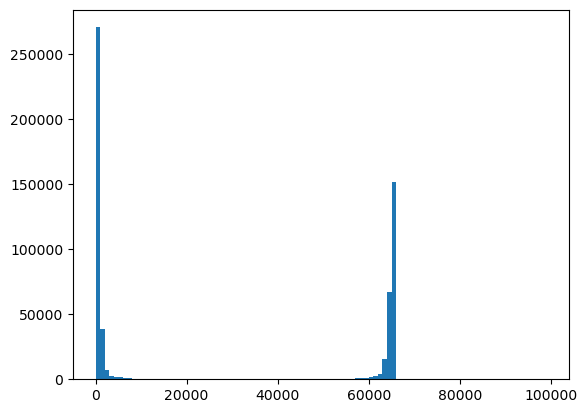

In [97]:
plt.hist(np.abs(im1[:,:,500] -im2[:,:,500]).flatten(), bins=np.arange(0,100000,1000))
# plt.hist(np.abs(im1[:,:,500] -im2_aligned[:,:,500]).flatten())

(array([20732.,  4814.,  4707.,  4685.,  4820.,  4890.,  4780.,  4808.,
         4734.,  4896.,  4777.,  4741.,  4616.,  4684.,  4654.,  4641.,
         4696.,  4771.,  4458.]),
 array([ 0.,  5., 10., 15., 20., 25., 30., 35., 40., 45., 50., 55., 60.,
        65., 70., 75., 80., 85., 90., 95.]),
 <BarContainer object of 19 artists>)

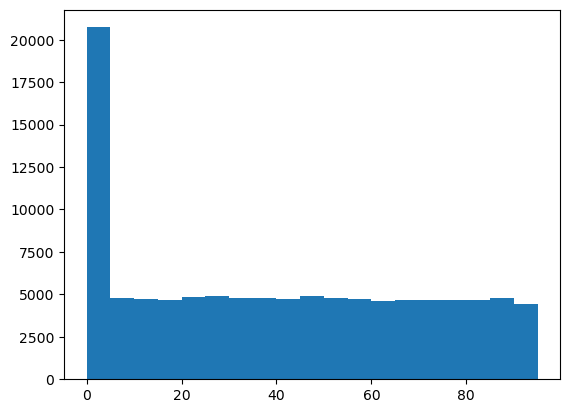

In [98]:
plt.hist(np.abs(im1[:,:,500] -im2_aligned[:,:,500]).flatten(), bins=np.arange(0,100,5))

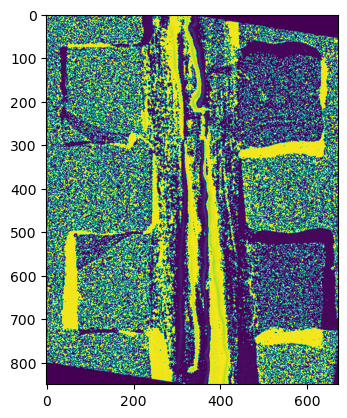

In [99]:
plt.imshow(np.abs(im1[:,:,500] -im2[:,:,500]))

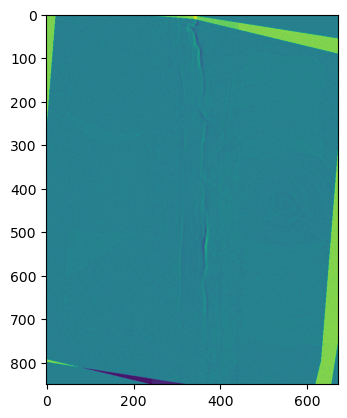

In [103]:
plt.imshow(im1[:,:,500] -im2_aligned[:,:,500])

(array([5.13142e+05, 2.03770e+04, 6.52500e+03, 3.67100e+03, 1.61300e+03,
        6.19600e+03, 1.78260e+04, 1.02000e+02, 1.80000e+01, 3.00000e+01]),
 array([    0.        ,  2050.60009766,  4101.20019531,  6151.79980469,
         8202.40039062, 10253.        , 12303.59960938, 14354.20019531,
        16404.80078125, 18455.40039062, 20506.        ]),
 <BarContainer object of 10 artists>)

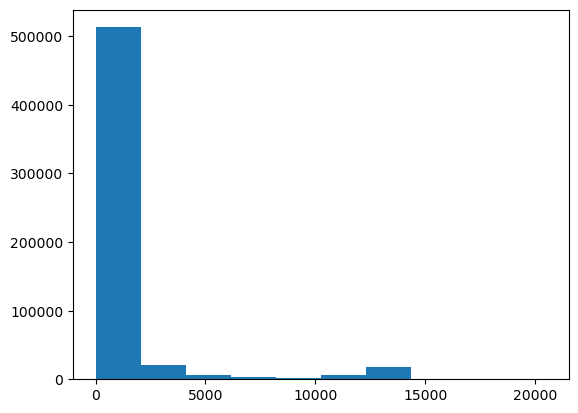

In [101]:
plt.hist(np.abs(im2[:,:,500] -im2_aligned[:,:,500]).flatten())

In [29]:
im2.max()

53678

In [30]:
im1.max()

53732

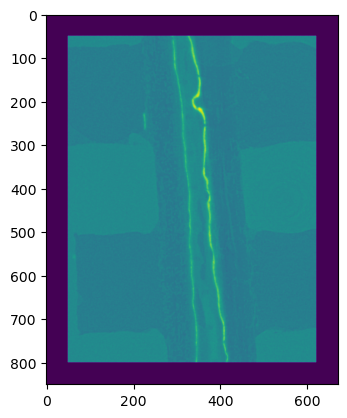

In [94]:
plt.imshow((im2*mask)[:,:,500])

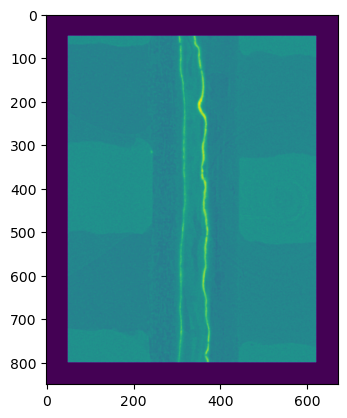

In [95]:
plt.imshow((im1*mask)[:,:,500])